# La transition vers la voiture électrique en France

Ouvrir ce notebook à la racine du dépôt. Le classeur AAV est nécessaire pour construire le référentiel communal. Les autres fichiers sont listés dans le README.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src import config, preparation, fusion, indicateurs, graphiques

disponible = {nom: preparation.chemin_brut(nom).is_file() for nom in config.FICHIERS}
display(pd.DataFrame([
    {"source": nom, "fichier": fichier, "présent": disponible[nom]}
    for nom, fichier in config.FICHIERS.items()
]))
if not disponible["aav"]:
    raise FileNotFoundError(f"Classeur AAV manquant : {preparation.chemin_brut('aav')}")


,source,fichier,présent
0,parc,Donnees-sur-le-parc-de-vehicules-au-niveau-com...,True
1,neuf,Immatriculations-de-vehicules-achetes-neufs-au...,False
2,occasion,Immatriculations-de-vehicules-achetes-doccasio...,False
3,aav,AAV2020_au_01-01-2026.xlsx,True
4,filosofi,DS_FILOSOFI_CC_2023_data.csv,True
5,irve,consolidation-etalab-schema-irve-statique-v-2_...,True
6,bpe,DS_BPE_2025_data.csv,False
7,population,DS_POPULATIONS_REFERENCE_2023_data.csv,True
8,contours,communes-50m.geojson,False


## 1. Référentiel communal

In [2]:
referentiel = preparation.preparer_aav()
print(f"{len(referentiel):,} communes dans le référentiel.")


34,746 communes dans le référentiel.


## 2. Préparation des sources

In [3]:
tables = {}

for nom in ("parc", "neuf", "occasion"):
    if disponible[nom]:
        est_parc = nom == "parc"
        colonne = f"PARC_{config.ANNEE_PARC}" if est_parc else f"IMMAT_{config.ANNEE_IMMAT}"
        brut = preparation.lire_fichier_sdes(nom, [colonne])
        tables[nom] = preparation.preparer_vehicules(
            brut, colonne,
            config.ELEC_PARC if est_parc else config.ELEC_IMMAT,
            config.MENAGE_PARC if est_parc else config.MENAGE_IMMAT,
            nom,
        )

for nom, preparer in (
    ("filosofi", preparation.preparer_filosofi),
    ("population", preparation.preparer_population),
    ("bpe", preparation.preparer_bpe),
):
    if disponible[nom]:
        tables[nom] = preparer()

if disponible["irve"]:
    tables["irve"], points = preparation.preparer_irve(referentiel["code_commune"])
    display(points["rattachement"].value_counts())


Lignes dans le fichier IRVE : 157,460
Doublons d'identifiant supprimés : 7,919
Contours communaux absents (communes-50m.geojson).
Pas de rattachement des bornes par coordonnées.


rattachement
code Insee     78942
non apparié    70599
Name: count, dtype: int64

## 3. Jointures et couverture des sources

In [4]:
if tables:
    base, couverture = fusion.construire_base(referentiel, tables)
    display(couverture)
else:
    base = referentiel.copy()
    print("Aucune source à joindre au référentiel.")


,communes du référentiel,communes appariées,communes sans donnée,codes de la source hors référentiel
source,,,,
parc,34746,34742,4,230
filosofi,34746,34744,2,24
population,34746,34746,0,112
irve,34746,6986,27760,0


## 4. Indicateurs et contrôles

In [5]:
colonnes_sources = [
    f"vp_{nom}{suffixe}"
    for nom in ("parc", "neuf", "occasion")
    for suffixe in ("", "_elec", "_men", "_elec_men")
] + [
    "niveau_vie_median", "population", "nb_points", "nb_points_rapides",
    "nb_gares", "nb_equip_transport",
]

for colonne in colonnes_sources:
    if colonne not in base:
        base[colonne] = float("nan")

base = indicateurs.calculer_indicateurs(
    base, irve_exhaustif=disponible["irve"], bpe_exhaustive=disponible["bpe"]
)
base["gare"] = base["gare"].where(base["nb_gares"].notna())
base, bornes_revenu = indicateurs.ajouter_groupes_revenu(base)
base = indicateurs.ajouter_classes_recharge(base)
display(indicateurs.controler_base(base))


,effectifs négatifs,électriques > total,"parts hors [0, 100]",parts indéfinies
table,,,,
parc,0,0,0,4
neuf,0,0,0,34746
occasion,0,0,0,34746


## 5. Tableaux et graphiques

,nb_communes,part VE parc (%),points de charge,points pour 100 VE,points pour 1 000 hab.
region,,,,,
Auvergne-Rhône-Alpes,4025,3.62,8707.0,4.73,1.06
Bourgogne-Franche-Comté,3685,2.56,2789.0,5.99,1.00
Bretagne,1202,3.04,3726.0,5.53,1.08
Centre-Val de Loire,1754,2.85,2302.0,4.93,0.89
Corse,360,4.99,294.0,2.63,0.83
Grand Est,5115,3.31,5829.0,5.10,1.05
Hauts-de-France,3782,3.29,8430.0,7.23,1.41
Normandie,2644,3.29,5859.0,8.48,1.75
Nouvelle-Aquitaine,4293,3.01,6806.0,5.60,1.11


array([12420., 24090., 25780., 27830., 62730.])

,nb_communes,q1,mediane,q3,vp_elec,vp_total,part_agregee
position_aav,,,,,,,
Pôle,1713,2.20,2.87,3.75,629594.0,16737786.0,3.76
Couronne,24156,1.83,2.81,3.99,687730.0,19248811.0,3.57
Hors attraction,8873,1.00,1.92,2.94,71700.0,3014655.0,2.38


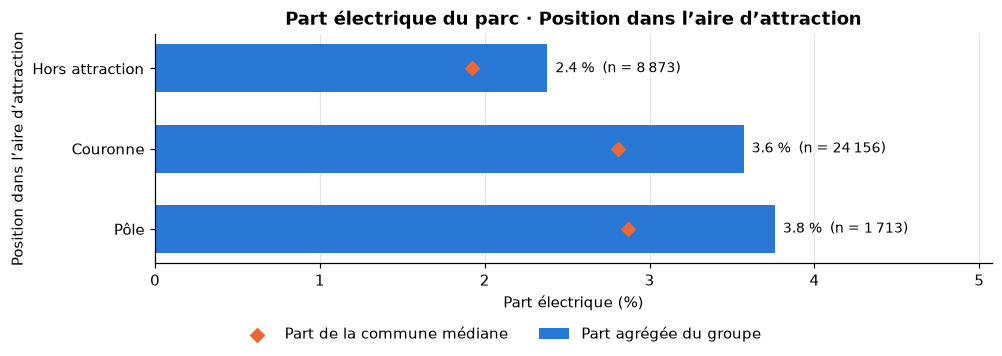

,nb_communes,q1,mediane,q3,vp_elec,vp_total,part_agregee
groupe_revenu,,,,,,,
Q1 (plus modestes),7701,1.22,1.93,2.68,335314.0,11713531.0,2.86
Q2,7698,1.57,2.34,3.13,222242.0,7588756.0,2.93
Q3,7688,2.04,2.86,3.74,279918.0,8030868.0,3.49
Q4 (plus aisées),7683,2.97,3.97,5.08,547416.0,11465819.0,4.77


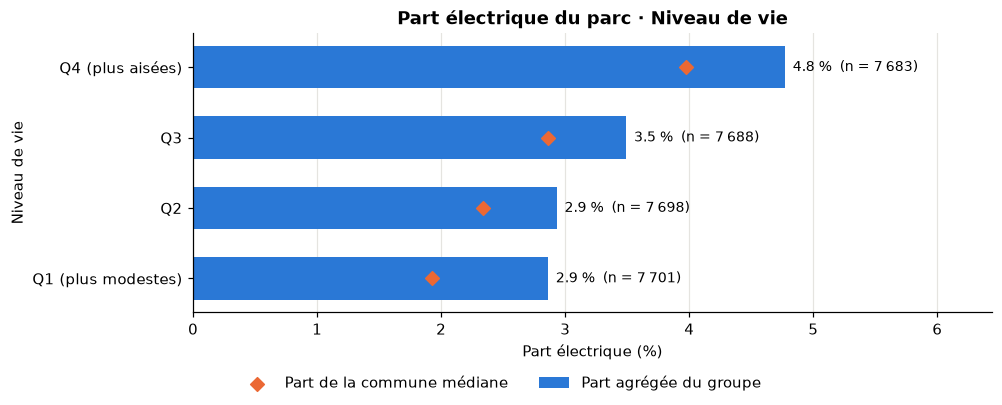

,nb_communes,q1,mediane,q3,vp_elec,vp_total,part_agregee
classe_recharge,,,,,,,
Aucun point recensé,27756,1.44,2.44,3.58,395161.0,12792655.0,3.09
Faible,2329,2.52,3.23,4.18,545090.0,14797177.0,3.68
Moyenne,2328,2.28,3.11,4.20,342020.0,8754496.0,3.91
Élevée,2329,1.98,2.99,4.28,106753.0,2656924.0,4.02


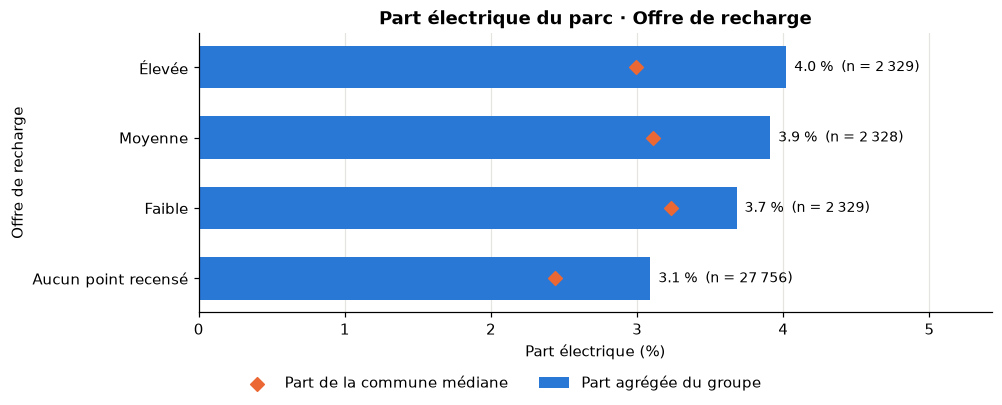

In [6]:
display(indicateurs.tableau_synthese(base))
if bornes_revenu is not None:
    display(bornes_revenu)

graphiques.appliquer_style()
for groupe, libelle in (
    ("position_aav", "Position dans l’aire d’attraction"),
    ("groupe_revenu", "Niveau de vie"),
    ("classe_recharge", "Offre de recharge"),
):
    if groupe not in base:
        continue
    resume = indicateurs.resume_par_groupe(base, groupe)
    if not resume.empty:
        display(resume)
        graphiques.tracer_barres(
            resume, f"Part électrique du parc · {libelle}",
            f"parc_{groupe}", label_groupe=libelle, trier=False,
        )
        plt.show()

if disponible["contours"] and base["part_parc"].notna().any():
    graphiques.tracer_carte(base, "part_parc", "Part électrique du parc", "carte_communes")
    plt.show()


## 6. Export de la base communale

In [7]:
config.DOSSIER_PREP.mkdir(parents=True, exist_ok=True)
sortie = config.DOSSIER_PREP / "base_communale.csv"
base.to_csv(sortie, index=False)
print(sortie.relative_to(config.RACINE))


data\processed\base_communale.csv


## 7. Conclusion

L’exécution enregistrée initialement a permis de constituer un référentiel de **34 746 communes de France métropolitaine**. Le fichier du parc automobile était absent et la part de voitures électriques restait indéfinie pour les 34 746 communes. Il était donc impossible de mesurer les écarts selon la position dans l’aire d’attraction, le niveau de vie ou l’offre de recharge.

Après ajout du parc automobile, de Filosofi, des données IRVE et de la population, la cellule ci-dessous résume les écarts observés. Elle compare les médianes des parts communales. Les différences mesurées sont descriptives et ne permettent pas d’établir un effet causal.

In [8]:
from IPython.display import Markdown

paragraphes = []
for groupe, titre, fichiers in (
    ("position_aav", "Position dans l’aire d’attraction", ("parc",)),
    ("groupe_revenu", "Niveau de vie", ("parc", "filosofi")),
    ("classe_recharge", "Offre de recharge", ("parc", "irve", "population")),
):
    manquants = [nom for nom in fichiers if not disponible[nom]]
    if manquants:
        paragraphes.append(f"**{titre}.** Comparaison indisponible. Sources manquantes : {', '.join(manquants)}.")
        continue

    resume = indicateurs.resume_par_groupe(base, groupe)
    if len(resume) < 2:
        paragraphes.append(f"**{titre}.** Moins de deux groupes disposent d’une part électrique calculable.")
        continue

    valeurs = " ; ".join(
        f"{nom} : {ligne['mediane']:.2f} % ({int(ligne['nb_communes'])} communes)"
        for nom, ligne in resume.iterrows()
    ).replace(".", ",")
    ecart = f"{resume['mediane'].max() - resume['mediane'].min():.2f}".replace(".", ",")
    paragraphes.append(
        f"**{titre}.** Parts médianes par groupe : {valeurs}. "
        f"L’écart entre la médiane la plus élevée et la plus faible est de {ecart} points de pourcentage."
    )

display(Markdown("\n\n".join(paragraphes)))


**Position dans l’aire d’attraction.** Parts médianes par groupe : Pôle : 2,87 % (1713 communes) ; Couronne : 2,81 % (24156 communes) ; Hors attraction : 1,92 % (8873 communes). L’écart entre la médiane la plus élevée et la plus faible est de 0,95 points de pourcentage.

**Niveau de vie.** Parts médianes par groupe : Q1 (plus modestes) : 1,93 % (7701 communes) ; Q2 : 2,34 % (7698 communes) ; Q3 : 2,86 % (7688 communes) ; Q4 (plus aisées) : 3,97 % (7683 communes). L’écart entre la médiane la plus élevée et la plus faible est de 2,04 points de pourcentage.

**Offre de recharge.** Parts médianes par groupe : Aucun point recensé : 2,44 % (27756 communes) ; Faible : 3,23 % (2329 communes) ; Moyenne : 3,11 % (2328 communes) ; Élevée : 2,99 % (2329 communes). L’écart entre la médiane la plus élevée et la plus faible est de 0,79 points de pourcentage.

## Conclusion
En France métropolitaine, la part médiane de voitures électriques dans le parc communal augmente à chaque quartile de niveau de vie. Elle passe de 1,93 % dans le quartile des communes les plus modestes à 2,34 %, puis 2,86 %, et atteint 3,97 % dans le quartile des communes les plus aisées. L’écart entre les deux quartiles extrêmes est de 2,04 points de pourcentage, le plus marqué des trois comparaisons.

La position dans l’aire d’attraction fait également apparaître un écart. Les médianes sont très proches dans les pôles (2,87 %) et les couronnes (2,81 %). Elles sont plus faibles dans les communes hors attraction (1,92 %), soit 0,95 point de moins que dans les pôles.

Enfin, les communes sans point de recharge recensé ont la médiane la plus faible (2,44 %). Parmi les communes équipées, la médiane est de 3,23 % lorsque la densité de recharge est faible, de 3,11 % lorsqu’elle est moyenne et de 2,99 % lorsqu’elle est élevée. La présence d’un point de recharge est donc associée à une part électrique médiane plus élevée dans ces données, et cette part ne croît pas avec le nombre de points de recharge par habitant.

Ces comparaisons sont descriptives. Les groupes peuvent aussi différer par leur niveau de vie, leur localisation ou d’autres caractéristiques. Les écarts observés ne permettent donc pas d’isoler l’effet propre de chaque facteur.
